In [12]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import math
import mpmath
import sympy as sp

In [13]:

M = 1

def R_s(r,b):
    return 1 - (b**2/r**2)*(1 - 2*M/r)

def Phi(b,R=100,r_t=10): #Leg
    integrand = lambda r: b/r**2/np.sqrt(R_s(R,b))
    return   scipy.integrate.quad(integrand, r_t,R)

def T(b,R=100,r_t=10): #Leg
    integrand = lambda r: 1/((1-2*M/r)*np.sqrt(R_s(R,b)))
    return   scipy.integrate.quad(integrand, r_t,R)
    

In [14]:
def I(b,R=100,r_t=10):
    return T(b)[0] - b*Phi(b)[0]

def I_n(b,n,R=100,r_t=10):
    return I(b) + (np.pi+2*np.pi*n)*b

def t_dn(b,phi,n,beta_s = 0, td_ref = 0,R=100,r_t=10):
    return I_n(b,n) - b*beta_s*np.cos(phi) - td_ref


In [15]:
rs = 10*M
phi_s = np.pi - np.pi/36
bc = 3*np.sqrt(3)*M
bmax = (rs**3/(rs-2*M))**0.5

b = np.linspace(bc, bmax, 100)
phi = np.linspace(0, 2*np.pi, 100)
B,P = np.meshgrid(b,phi)
X = B*np.cos(P)
Y = B*np.sin(P)

t_dvec = np.vectorize(t_dn)
#Vectorize, what a wonderful method
t_0 = lambda arg: t_dvec(arg[0],arg[1],0)

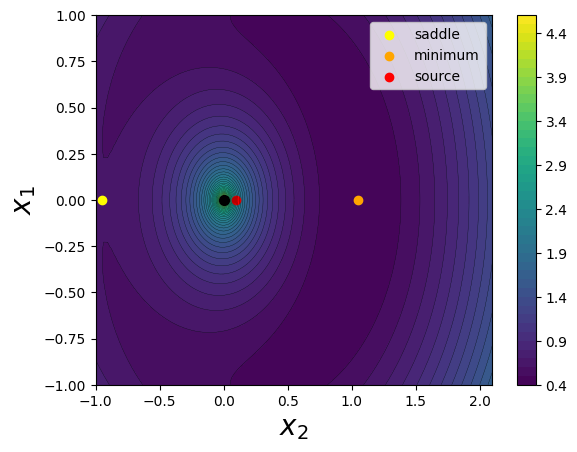

In [16]:
a = np.linspace(-1, 2.1, 100)
b = np.linspace(-1, 1, 100)
X,Y = np.meshgrid(a,b)

def T_PML(x_1,x_2,y_1,y_2,phi_m=0):
    return 0.5*((x_1-y_1)**2+(x_2-y_2)**2) - np.log(((x_1)**2+(x_2)**2)**0.5) - phi_m
    
y = np.array([0.1,0])
alfa = np.arctan(y[1]/y[0])

x_p_mod = 0.5*(np.sqrt(y@y)+np.sqrt(y@y+4))#min
x_p = np.array([x_p_mod*np.cos(alfa),x_p_mod*np.sin(alfa)])

x_m_mod = 0.5*(np.sqrt(y@y)-np.sqrt(y@y+4))#saddle
x_m = np.array([x_m_mod*np.cos(alfa),x_m_mod*np.sin(alfa)])
 

T_lam = lambda x: T_PML(x[0],x[1],*y)
phi_m = scipy.optimize.minimize(T_lam,[1,1]).fun
T_vec = np.vectorize(T_PML)

Tplot, ax = plt.subplots()

cf = ax.contourf(X,Y,T_vec(X,Y,*y), levels = 50)
ax.contour(X,Y,T_vec(X,Y,*y), levels = 50, colors = "k", linewidths = 0.2)
Tplot.colorbar(cf, ax = ax)
ax.scatter(*x_m, color = "yellow", label = "saddle")
ax.scatter(*x_p, color = "orange", label = "minimum")
ax.scatter(*y, color = "red", label = "source")
ax.scatter(0,0,color = "black", linewidth = 2)
ax.set_xlabel("$x_2$", size = 20)
ax.set_ylabel("$x_1$", size = 20)
ax.legend()


Tplot.savefig("Tplot")

In [17]:
#ANALYTICAL SOLUTIONS

def phi_m(y):
    return 1/8*(np.sqrt(y@y+4)-(y@y)**0.5)**2-np.log( ((y@y)**0.5 + np.sqrt(y@y + 4)) / 2)
    
def F_ana(w,y):
    #w = w*(1+z_L)*epsi_0**2*D_S/(D_L*D_LS)
    
    pref = np.exp(np.pi*w/4+1j*w/2*(np.log(w/2)-2*phi_m(y)))
    val = mpmath.gamma(1-1j*w/2)*mpmath.hyp1f1(1j*w/2,1,1j*w*y@y/2)
    val = complex(val)
    pref = complex(pref)
    return np.abs(pref*val)

      

In [30]:
#GEOMETRIC SOLUTIONS

def T_ab_fun(T,p,y, phi_m = 0, tau = 1):
    T_lam = lambda x: T(*x,*y)
    hess = scipy.differentiate.hessian(T_lam,p)
#    return hess.ddf/tau
    return hess.ddf/tau

def mag(T,x_j,y):
    T_ab = T_ab_fun(T,x_j,y)
    return complex(1/np.linalg.det(T_ab))

def DeltaT(T,x_1,x_2,y):
    return np.abs(T(*x_1,*y) - T(*x_2, *y))

def F_geo(T,w,y,x_m):
    val_1 = np.abs(mag(T, x_m[0],y))**0.5 
    val_2 = np.abs(mag(T, x_m[1],y))**0.5*np.exp(1j*(w*DeltaT(T,*x_m,y)-np.pi/2))
    
    val = val_1 + val_2
    return val

In [54]:
#GEOMETRIC CORRECTION SOLUTION

def Delta(x):
    x2 = x@x
    return (4*x2-1)/(3*((x2+1)**3)*(x2-1))

def F_geo_corr(T,w,y,x0):
    val_1 = (1+1j/w*Delta(x0[0]))*np.abs(mag(T, x0[0],y))**0.5 
    val_2 = (1+1/w*Delta(x0[1]))*np.abs(mag(T, x0[1],y))**0.5*np.exp(1j*(w*DeltaT(T,*x0,y)-np.pi/2))
    
    val = val_1 + val_2
    return val

In [66]:
y = np.array([0.1,0])
alfa = np.arctan(y[1]/y[0])

x_plus_mod = 0.5*(np.sqrt(y@y)+np.sqrt(y@y+4))#min
x_plus = np.array([x_p_mod*np.cos(alfa),x_p_mod*np.sin(alfa)])

x_minus_mod = 0.5*(np.sqrt(y@y)-np.sqrt(y@y+4))#saddle
x_minus = np.array([x_m_mod*np.cos(alfa),x_m_mod*np.sin(alfa)])

w = np.linspace(0.1,50,50)


In [67]:
F_geo_corr_vec=np.vectorize(F_geo_corr,excluded={0},signature = "(),(k),(n,m)->()")
F_geo_corr_vals = F_geo_corr_vec(T_PML,w,y,[x_plus,x_minus])

In [68]:
F_geo_vec=np.vectorize(F_geo,excluded={0},signature = "(),(k),(n,m)->()")
F_geo_vals = F_geo_vec(T_PML,w,y,[x_plus,x_minus])

In [69]:
F_ana_vec=np.vectorize(F_ana,signature = "(),(k)->()")
F_ana_vals = F_ana_vec(w,y)


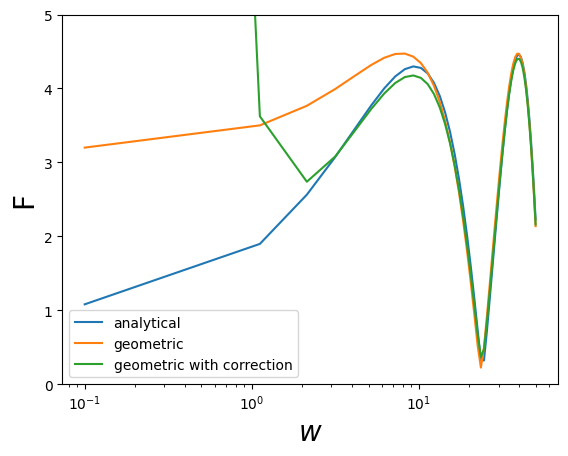

In [70]:
Fplot = plt.figure()
plt.semilogx(w,np.abs(F_ana_vals), label = "analytical")
plt.semilogx(w,np.abs(F_geo_vals), label = "geometric")
plt.semilogx(w,np.abs(F_geo_corr_vals), label = "geometric with correction")
plt.xlabel("$w$", size=20)
plt.ylabel("F", size = 20)
plt.ylim(0,5)
plt.legend()
plt.savefig("F plot")



In [ ]:
def F_num(T,w,y1,y2):
    T_real = lambda b,phi: np.exp(1j*T(b*np.cos(phi),b*np.sin(phi),y1,y2)*w).real*b
    T_im = lambda b,phi: np.exp(1j*T(b*np.cos(phi),b*np.sin(phi),y1,y2)*w).imag*b
    real = scipy.integrate.dblquad(T_real,0,2*np.pi,0.1,5)[0]
    im = scipy.integrate.dblquad(T_im,0,2*np.pi,0.1,5)[0]
    return w/(2*np.pi*1j)*(real+1j*im)

F_num_vec = np.vectorize(F_num)
F_num_vals = F_num_vec(T_PML,w,*y)
plt.

In [ ]:
t_ref = scipy.optimize.minimize(t_0,x0=[7,np.pi],bounds=((bc,bmax),(0,2*np.pi)))
[b_ref,phi_ref] = t_ref.x
t_ref = t_ref.fun
time_surf = t_dvec((X**2+Y**2)**0.5,np.arctan(Y/X),n=0,td_ref = t_ref)
plt.contourf(X,Y,time_surf, levels = 10)
plt.scatter(b_ref*np.cos(phi_ref),b_ref*np.sin(phi_ref))

In [10]:
#time_surf = np.array([[t_dn((i**2+j**2)**0.5,np.arctan(j/i),10) for i in bx*M] for j in by*M])
#plt.contourf(X,Y,time_surf, levels = 50)

In [ ]:
"""
def F_ana_old(w,y_1,y_2,x_m_1,x_m_2):
    x_m = np.array([x_m_1,x_m_2])
    
    pref = mpmath.exp(np.pi*w/4+1j*w/2*(np.log(w/2)-2*T_PML(*x_m,*y)))
    val = mpmath.gamma(1-1j*w/2)*mpmath.hyp1f1(1j*w/2,1,1j*w*y@y/2)

    return complex(pref*val)


def F_geo_old(T,w,y,x0): #HANDLES MULTIPLE IMAGES
    val = 0
    T_min = T(*x0[0][:2],*y)
    for i in x0:
        mu_j = mag(T,i[:2],y)
        val = val + np.abs(mu_j)**0.5*np.exp(1j*(w*(T(i[0],i[1],y[0],y[1])-T_min) - np.sign(w)*i[2]*np.pi/2))
    return val

"""